<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Classical NLP](https://github.com/Query-farm/vgi-nlp)

Detect language, score sentiment, extract entities and tokenize text from queries.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nlp/blob/main/notebooks/02_trace_extracted_spans_to_text.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nlp/blob/main/notebooks/README.md)

## Do extracted spans still identify their source?

A table-valued extractor can emit several rows for one document and none for another. Keep the full six-document roster, split sentences and extract named entities with the same English pipeline, then verify that every returned entity span reconstructs from the exact processed text.

All documents below are invented examples, including an ordinary text with no intended named entities, accented characters, empty text and NULL. A model label is an output to inspect, not confirmed knowledge about a real person or organization. **`TEXT_FORM` selects original or normalized text**. The experiment lowercases and collapses whitespace through the released normalizer; offsets must always refer to that selected form.

In [1]:
TEXT_FORM = "original"  # Experiment: "normalized".

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.49":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from pathlib import Path
import os

check_runtime()
prepare("nlp")
import nlp_example as example

assert TEXT_FORM in ("original","normalized")
previous_download = os.environ.get("VGI_NLP_NO_MODEL_DOWNLOAD")
os.environ["VGI_NLP_NO_MODEL_DOWNLOAD"] = "1"
session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()

### Attach the released worker and select English explicitly

The short literal Git launcher pins **v0.4.0**, with its declared dependencies in a separate worker environment. The release includes the official **`en_core_web_sm` 3.8.0** wheel; no local checkout or transitive package overrides are needed. First use requires network for packages and the published VGI extension; NLP computation remains local.

The supported-language table maps language codes to default model names. It does **not** prove every listed model is installed. We require its English mapping to match `en_core_web_sm`, then explicitly pass both language and model to spaCy calls. These authored English inputs need no automatic language detection: optional fastText downloads are disabled, and cleanup restores the previous setting. Other models and languages are not tested here.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nlp' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nlp@v0.4.0 vgi-nlp-worker');
CREATE TABLE language_catalog AS SELECT * FROM nlp.main.supported_languages();
CREATE TABLE selected_language AS SELECT * FROM language_catalog WHERE lang_code='en';

,Count


In [5]:
%%sql language <<
SELECT *, (SELECT count(*) FROM language_catalog) AS advertised_languages FROM selected_language;

In [6]:
display(language)
assert len(language)==1 and language.lang_code.iloc[0]=='en' and language.spacy_model.iloc[0]=='en_core_web_sm'
prose(f"**English maps to {language.spacy_model.iloc[0]}** in the {int(language.advertised_languages.iloc[0])}-language registry. This selected row is checked before model calls. Registry membership describes routing metadata; only the released English pipeline is exercised.")

,lang_code,spacy_model,advertised_languages
0,en,en_core_web_sm,24


**English maps to en_core_web_sm** in the 24-language registry. This selected row is checked before model calls. Registry membership describes routing metadata; only the released English pipeline is exercised.

### Preserve original and processed text separately

The source keeps an integer ID, an author label and the original body. `normalize` uses Unicode NFKC, lowercase and whitespace collapse; multiple spaces in the first document make its coordinate change visible. The selected body is materialized before either extractor runs. Original text remains inspectable even when model input changes.

The left-join audit will retain empty/NULL inputs as zero emitted rows. That means the known input produced no rows under this pipeline; it does not mean that a missing document contains zero real-world entities.

In [7]:
%%sql
CREATE TABLE documents(id,case_name,original_text) AS VALUES
 (1,'Two sentences','Apple Inc.  opened an office in Paris.   Steve Jobs spoke on Tuesday.'),
 (2,'Ordinary text','The release arrived. It contains several fixes.'),
 (3,'Place and month','Visit New York in June.'),
 (4,'Accented name','Zoë paid $25 on Monday.'),
 (5,'Empty text',''),
 (6,'Missing text',NULL::VARCHAR);
CREATE TABLE transformed AS SELECT *,nlp.main.normalize(original_text) AS normalized_text FROM documents;
CREATE TABLE processed AS SELECT *,CASE WHEN '{{TEXT_FORM}}'='original' THEN original_text ELSE normalized_text END AS input_text FROM transformed;
SELECT id,case_name,original_text,input_text,length(original_text) AS original_characters,length(input_text) AS processed_characters FROM processed ORDER BY id;

,id,case_name,original_text,input_text,original_characters,processed_characters
0,1,Two sentences,Apple Inc. opened an office in Paris. Steve...,Apple Inc. opened an office in Paris. Steve...,69,69
1,2,Ordinary text,The release arrived. It contains several fixes.,The release arrived. It contains several fixes.,47,47
2,3,Place and month,Visit New York in June.,Visit New York in June.,23,23
3,4,Accented name,Zoë paid $25 on Monday.,Zoë paid $25 on Monday.,23,23
4,5,Empty text,,,0,0
5,6,Missing text,None,None,<NA>,<NA>


### Materialize each extractor before joining its results

Both table-in-out calls pass the same ID, explicit text-column name, English language and released model. Sentence indices are zero-based **within each document**. Entity offsets are zero-based, half-open **character positions**: `[start_char, end_char)`. They are not byte offsets or positions in the original body after normalization.

Store the outputs separately. Joining raw sentence rows directly to raw entity rows by document ID would multiply rows and inflate counts. Instead, aggregate each output independently before joining back to the six-document roster.

In [8]:
%%sql
CREATE TABLE sentence_rows AS SELECT * FROM nlp.main.sentences(
 (SELECT id,input_text FROM processed),id:='id',text:='input_text',lang:='en',model:='en_core_web_sm');
CREATE TABLE entity_rows AS SELECT * FROM nlp.main.entities(
 (SELECT id,input_text FROM processed),id:='id',text:='input_text',lang:='en',model:='en_core_web_sm');
CREATE TABLE span_audit AS
SELECT e.*,substr(p.input_text,e.start_char+1,e.end_char-e.start_char) AS reconstructed,
 substr(p.input_text,e.start_char+1,e.end_char-e.start_char)=e.ent_text AS matches_processed_text
FROM entity_rows e JOIN processed p USING(id);
SELECT * FROM span_audit ORDER BY id,start_char,end_char;

,id,ent_text,label,start_char,end_char,reconstructed,matches_processed_text
0,1,Apple Inc.,ORG,0,10,Apple Inc.,True
1,1,Paris,GPE,32,37,Paris,True
2,1,Steve Jobs,PERSON,41,51,Steve Jobs,True
3,1,Tuesday,DATE,61,68,Tuesday,True
4,3,New York,GPE,6,14,New York,True
5,3,June,DATE,18,22,June,True
6,4,Zoë,PERSON,0,3,Zoë,True
7,4,25,MONEY,10,12,25,True
8,4,Monday,DATE,16,22,Monday,True


In [9]:
%%sql sentences <<
SELECT s.id,p.case_name,s.sent_index,s.sentence FROM sentence_rows s JOIN processed p USING(id) ORDER BY s.id,s.sent_index;

In [10]:
display(sentences)
prose(f"The sentence extractor emitted **{len(sentences)} rows**. Its sentence text is trimmed by the worker, so these strings are not an exact reconstruction of inter-sentence whitespace. Entity span reconstruction below is a separate character-offset check against the selected processed body.")

,id,case_name,sent_index,sentence
0,1,Two sentences,0,Apple Inc. opened an office in Paris.
1,1,Two sentences,1,Steve Jobs spoke on Tuesday.
2,2,Ordinary text,0,The release arrived.
3,2,Ordinary text,1,It contains several fixes.
4,3,Place and month,0,Visit New York in June.
5,4,Accented name,0,Zoë paid $25 on Monday.


The sentence extractor emitted **6 rows**. Its sentence text is trimmed by the worker, so these strings are not an exact reconstruction of inter-sentence whitespace. Entity span reconstruction below is a separate character-offset check against the selected processed body.

In [11]:
%%sql audit <<
WITH sentence_counts AS (SELECT id,count(*) AS sentence_count FROM sentence_rows GROUP BY id),
 entity_counts AS (SELECT id,count(*) AS entity_count,sum(end_char-start_char) AS entity_characters FROM entity_rows GROUP BY id)
SELECT p.id,p.case_name,p.original_text,p.input_text,
 coalesce(length(p.input_text),0) AS characters_for_accounting,p.input_text IS NULL AS missing_input,
 coalesce(s.sentence_count,0) AS sentence_count,coalesce(e.entity_count,0) AS entity_count,
 coalesce(e.entity_characters,0) AS entity_characters,
 coalesce(length(p.input_text),0)-coalesce(e.entity_characters,0) AS other_characters
FROM processed p LEFT JOIN sentence_counts s USING(id) LEFT JOIN entity_counts e USING(id) ORDER BY p.id;

### Keep zero-output documents in the denominator

The two panels count different emitted populations, so neither is a subset count of the other. Every original ID appears, including empty and missing input. Zero bars are labeled rather than dropped. Sentence/NER output depends on the pipeline and selected text; a zero entity count is not proof that the document has no meaningful subjects.

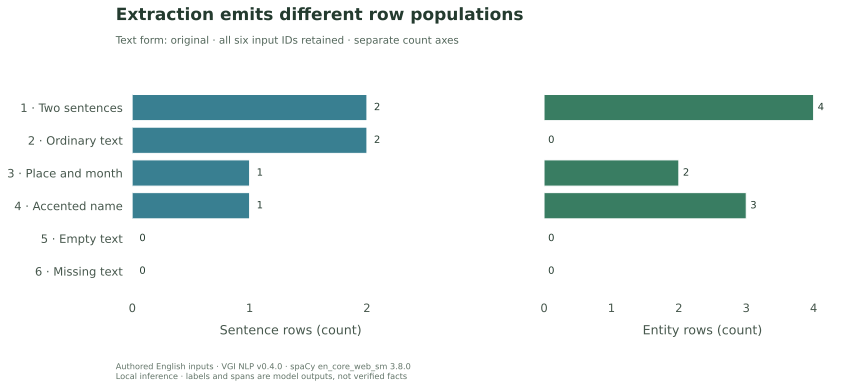

In [12]:
example.extraction_counts(audit,TEXT_FORM)

### Reconcile the returned character spans

For nonmissing text, sum the lengths of nonoverlapping entity spans and compare with total processed characters. The remaining characters include whitespace, punctuation and text not marked as an entity. This is **annotation coverage**, not entity-recognition recall: there are no independent reference annotations.

NULL input is labeled missing; its zero-length accounting row is only a device to keep the full roster visible. The SQL checks verify no overlapping spans before interpreting the sum. DuckDB substring positions start at 1, so reconstruction adds 1 to the worker's `start_char` and uses `end_char − start_char` as the length.

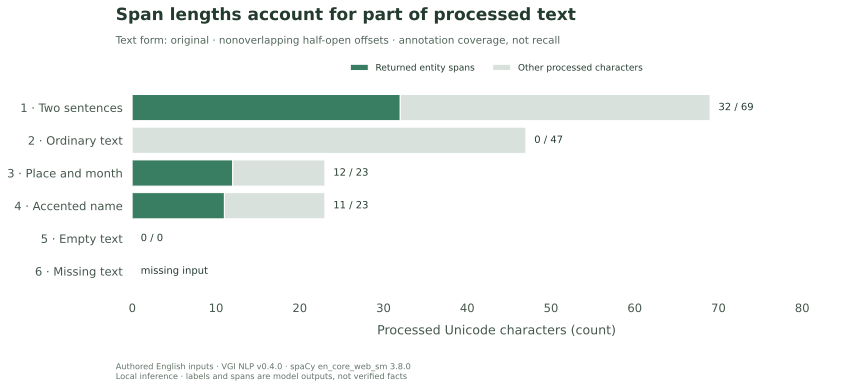

In [13]:
example.characters(audit,TEXT_FORM)

In [14]:
display(audit[["id","case_name","sentence_count","entity_count","entity_characters","other_characters","missing_input"]])
prose(f"With **{TEXT_FORM}** text, **{int(audit.sentence_count.sum())} sentence rows** and **{int(audit.entity_count.sum())} entity rows** map back to all **{len(audit)} input IDs**. Returned entity spans cover **{int(audit.entity_characters.sum())} of {int(audit.characters_for_accounting.sum())} processed characters** in nonmissing inputs. This is returned annotation coverage; no accuracy or completeness claim follows from it.")
export=Path("artifacts/data/02");export.mkdir(parents=True,exist_ok=True)
audit.to_csv(export/"audit.csv",index=False)
sentences.to_csv(export/"sentences.csv",index=False)
con.execute("SELECT * FROM span_audit ORDER BY id,start_char,end_char").df().to_csv(export/"entities.csv",index=False)

,id,case_name,sentence_count,entity_count,entity_characters,other_characters,missing_input
0,1,Two sentences,2,4,32.0,37.0,False
1,2,Ordinary text,2,0,0.0,47.0,False
2,3,Place and month,1,2,12.0,11.0,False
3,4,Accented name,1,3,11.0,12.0,False
4,5,Empty text,0,0,0.0,0.0,False
5,6,Missing text,0,0,0.0,0.0,True


With **original** text, **6 sentence rows** and **9 entity rows** map back to all **6 input IDs**. Returned entity spans cover **55 of 162 processed characters** in nonmissing inputs. This is returned annotation coverage; no accuracy or completeness claim follows from it.

### Verify identities, coordinate bounds and counts

These checks establish traceability of actual returned rows. They do not assert that any particular name or label is correct. Documents with no extractor output remain explicit, and the normalized experiment uses the same contracts.

In [15]:
%%sql checks <<
SELECT 'six unique input IDs are preserved' AS invariant,(SELECT count(*)=6 AND count(DISTINCT id)=6 FROM processed) AS passed
UNION ALL SELECT 'original bodies are unchanged',NOT EXISTS(SELECT 1 FROM processed p JOIN documents d USING(id) WHERE p.original_text IS DISTINCT FROM d.original_text)
UNION ALL SELECT 'sentence rows retain valid document IDs',NOT EXISTS(SELECT 1 FROM sentence_rows ANTI JOIN processed USING(id))
UNION ALL SELECT 'entity rows retain valid document IDs',NOT EXISTS(SELECT 1 FROM entity_rows ANTI JOIN processed USING(id))
UNION ALL SELECT 'entity spans have valid half-open character bounds',(SELECT bool_and(start_char>=0 AND end_char>start_char AND end_char<=length(p.input_text)) FROM entity_rows e JOIN processed p USING(id))
UNION ALL SELECT 'every entity reconstructs from processed text',(SELECT bool_and(matches_processed_text) FROM span_audit)
UNION ALL SELECT 'entity spans do not overlap',(SELECT bool_and(previous_end IS NULL OR start_char>=previous_end) FROM(SELECT *,lag(end_char) OVER(PARTITION BY id ORDER BY start_char,end_char) AS previous_end FROM entity_rows))
UNION ALL SELECT 'sentence indices are contiguous per emitted document',(SELECT bool_and(first_index=0 AND last_index=n-1 AND distinct_indices=n) FROM(SELECT id,min(sent_index) AS first_index,max(sent_index) AS last_index,count(*) AS n,count(DISTINCT sent_index) AS distinct_indices FROM sentence_rows GROUP BY id))
UNION ALL SELECT 'empty and NULL inputs emit no sentences',NOT EXISTS(SELECT 1 FROM sentence_rows s JOIN processed p USING(id) WHERE p.input_text IS NULL OR trim(p.input_text)='')
UNION ALL SELECT 'empty and NULL inputs emit no entities',NOT EXISTS(SELECT 1 FROM entity_rows e JOIN processed p USING(id) WHERE p.input_text IS NULL OR trim(p.input_text)='');

In [16]:
display(checks)
assert len(checks)==10 and checks.passed.fillna(False).all()
assert len(audit)==6 and (audit.entity_characters+audit.other_characters).eq(audit.characters_for_accounting).all()
assert audit.other_characters.ge(0).all()
assert audit.sentence_count.sum()==len(sentences)
assert audit.entity_count.sum()==con.execute("SELECT count(*) FROM entity_rows").fetchall()[0][0]
prose("**All 10 SQL checks and the output/character reconciliations passed.** Traceable spans are a data-contract result; inspecting semantic correctness requires separate judgments.")

,invariant,passed
0,six unique input IDs are preserved,True
1,original bodies are unchanged,True
2,sentence rows retain valid document IDs,True
3,entity rows retain valid document IDs,True
4,entity spans have valid half-open character bo...,True
5,every entity reconstructs from processed text,True
6,entity spans do not overlap,True
7,sentence indices are contiguous per emitted do...,True
8,empty and NULL inputs emit no sentences,True
9,empty and NULL inputs emit no entities,True


**All 10 SQL checks and the output/character reconciliations passed.** Traceable spans are a data-contract result; inspecting semantic correctness requires separate judgments.

### Focused experiment: normalize before extraction

Change only **`TEXT_FORM` from `"original"` to `"normalized"`**, restart and run all. Predict that lowercase and collapsed whitespace will change the text coordinates and may change model outputs. Compare exact processed text, reconstructed spans, sentence/entity counts and the character accounting bars. The original bodies and source IDs must remain unchanged.

A difference does not establish that either form is more accurate. Never reuse offsets from one text form to highlight another form. Restore **`"original"`** for the saved baseline; the README command writes the experiment separately.

In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
if previous_download is None:
    os.environ.pop("VGI_NLP_NO_MODEL_DOWNLOAD",None)
else:
    os.environ["VGI_NLP_NO_MODEL_DOWNLOAD"] = previous_download

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nlp](https://github.com/Query-farm/vgi-nlp)